
# 02425 Diffusion and stochastich differential equations


## WEEK 6: Itô calculus and SDE’

### Using Itō’s lemma to verify of solution

In [238]:
import numpy as np
import random
from numpy import random
from matplotlib import pyplot as plt
import scipy.stats as stats


### Exercise 1

We are interested in verifying that

$$
Y_t = \sinh(B_t)
$$

satisfies the following Itô SDE

$$
dY_t
=
\frac{1}{2}Y_t\,dt
+
\sqrt{1+Y_t^2}\,dB_t.
$$

We can use Itô's lemma. Let

$$
h(x)=\sinh(x),
$$

such that

$$
Y_t=h(B_t).
$$

The first and second derivatives are given as

$$
h'(x)=\cosh(x),
$$

and

$$
h''(x)=\sinh(x).
$$

By Itô's lemma,

$$
dY_t
=
h'(B_t)dB_t
+
\frac{1}{2}h''(B_t)(dB_t)^2.
$$

Since

$$
(dB_t)^2=dt,
$$

we get

$$
dY_t
=
\cosh(B_t)dB_t
+
\frac{1}{2}\sinh(B_t)dt.
$$

Since

$$
Y_t=\sinh(B_t),
$$

we have

$$
\sinh(B_t)=Y_t.
$$

Furthermore, using the identity

$$
\cosh^2(x)-\sinh^2(x)=1,
$$

we get

$$
\cosh(B_t)
=
\sqrt{1+\sinh^2(B_t)}
=
\sqrt{1+Y_t^2}.
$$

Therefore

$$
dY_t
=
\frac{1}{2}Y_t\,dt
+
\sqrt{1+Y_t^2}\,dB_t.
$$

Thus we have verified that $Y_t=\sinh(B_t)$ satisfies the given Itô SDE.

### Stochastic logistic growth

### Exercise 2

We have the Itô SDE

$$
dX_t
=
X_t(1-X_t)\,dt
+
\sigma X_t\,dB_t.
$$

We are interested in finding a Lamperti transformation

$$
Y_t=h(X_t)
$$

such that the transformed process has additive noise.

For an Itô SDE of the form

$$
dX_t=f(X_t)\,dt+g(X_t)\,dB_t,
$$

the Lamperti transformation is defined as

$$
h(x)
=
\int^x \frac{1}{g(v)}\,dv.
$$

In our case,

$$
g(x)=\sigma x.
$$

Therefore,

$$
h(x)
=
\int^x \frac{1}{\sigma v}\,dv.
$$

This gives

$$
h(x)
=
\frac{\ln(x)}{\sigma}.
$$

Hence,

$$
Y_t
=
\frac{\ln(X_t)}{\sigma}.
$$

The first and second derivatives are

$$
h'(x)
=
\frac{1}{\sigma x}
$$

and

$$
h''(x)
=
-\frac{1}{\sigma x^2}.
$$

By Itô's lemma,

$$
dY_t
=
h'(X_t)dX_t
+
\frac{1}{2}h''(X_t)g^2(X_t)\,dt.
$$

Substituting the expressions gives

$$
dY_t
=
\frac{1}{\sigma X_t}
\left(
X_t(1-X_t)\,dt
+
\sigma X_t\,dB_t
\right)
+
\frac{1}{2}
\left(
-\frac{1}{\sigma X_t^2}
\right)
\sigma^2 X_t^2\,dt.
$$

Therefore,

$$
dY_t
=
\left(
\frac{1-X_t}{\sigma}
-
\frac{\sigma}{2}
\right)dt
+
dB_t.
$$

Since

$$
Y_t=\frac{\ln(X_t)}{\sigma},
$$

we have

$$
X_t=e^{\sigma Y_t}.
$$

Hence,

$$
dY_t
=
\left(
\frac{1-e^{\sigma Y_t}}{\sigma}
-
\frac{\sigma}{2}
\right)dt
+
dB_t.
$$

Thus, the Lamperti transformation is

$$
Y_t=\frac{\ln(X_t)}{\sigma},
$$

and the transformed Itô equation has additive noise.

### Numerical analysis with the Euler-Maruyama metho

### Exercise 3

In [239]:
def Brownian(partition):

    BrownianMotion = np.array([])

    for i in range(len(partition)):

        if partition[i] == 0:
            BrownianMotion = np.append(BrownianMotion, 0)
        if partition[i] != 0:
            BrownianMotion = np.append(BrownianMotion, random.normal(loc=BrownianMotion[-1], scale=np.sqrt(partition[i]-partition[i-1])))

    return BrownianMotion



In [240]:
lmda = 1/2
gamma = 1
chsi = 2

T = 10
dt = 0.01
x = chsi



f = lambda x: lmda * (chsi - x)
g = lambda x: gamma*np.sqrt(np.abs(x))

k = 1
sigma = 0.2
x = 0.1

partition = np.linspace(0, T, int(T/dt))

Bt = Brownian(partition)

def eulersumL(f,g,T,dt,x):
    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    X[0] = x


    for i in range(1, N):

        X[i] = X[i-1] + X[i-1]*(k-X[i-1])*dt + sigma*X[i-1]*(Bt[i]-Bt[i-1])
        
    return t, X

t, XL = eulersumL(f, g, T, dt, x)

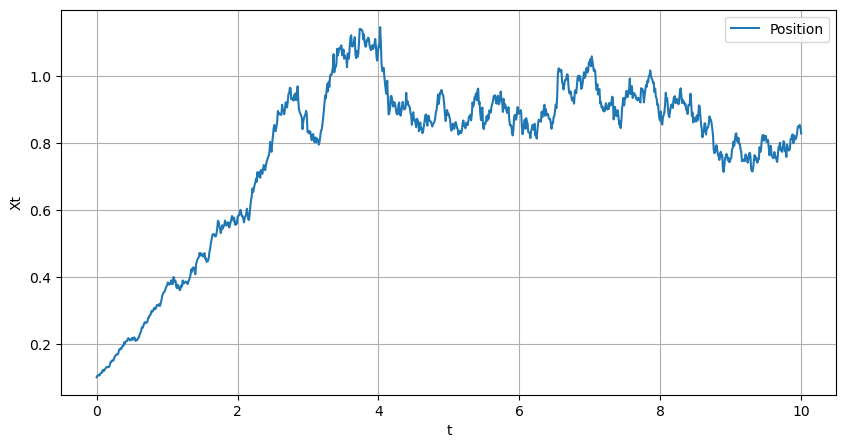

In [241]:
plt.figure(figsize=(10, 5))

plt.plot(t, XL, label="Position")

plt.xlabel("t")
plt.ylabel("Xt")
plt.legend()
plt.grid()

plt.show()

### Exercise 4

In [242]:
lmda = 1/2
gamma = 1
chsi = 2

T = 10
dt = 0.01
x = chsi



f = lambda x: lmda * (chsi - x)
g = lambda x: gamma*np.sqrt(np.abs(x))




sigma = 0.2
x = 0.1


partition = np.linspace(0, T, int(T/dt))

Bt = Brownian(partition)

def eulersumL(f,g,T,dt,x):
    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    Y = np.zeros(N)
    Z = np.zeros(N)
    X[0] = x
    Y[0] = np.log(x)/sigma
    Z[0] = np.log(x)/sigma


    for i in range(1, N):

        X[i] = X[i-1] + X[i-1]*(1-X[i-1])*dt + sigma*X[i-1]*(Bt[i]-Bt[i-1])
        Y[i] = Y[i-1] + ((1-np.exp(sigma*Y[i-1]))/sigma - sigma/2)*dt + (Bt[i]-Bt[i-1])
        Z[i] = Z[i-1] + 1/(sigma*X[i-1]) * (X[i]-X[i-1]) - 1/2 * 1/sigma*X[i-1]**2 * sigma**2 * X[i]**2 * dt

    return t, X, Y, Z

t, XL, YL, ZL = eulersumL(f, g, T, dt, x)

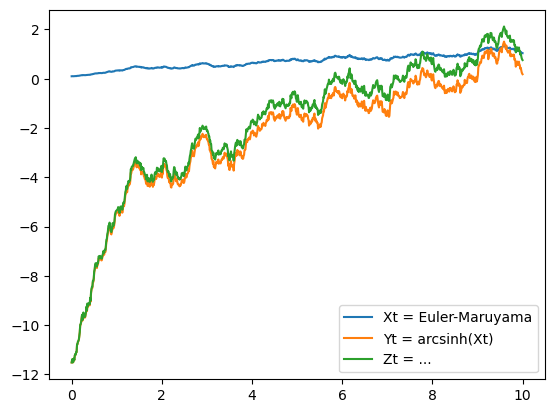

In [243]:
plt.plot(t, XL, label="Xt = Euler-Maruyama")
plt.plot(t, YL, label="Yt = arcsinh(Xt)")
plt.plot(t, ZL, label="Zt = ...")
plt.legend()

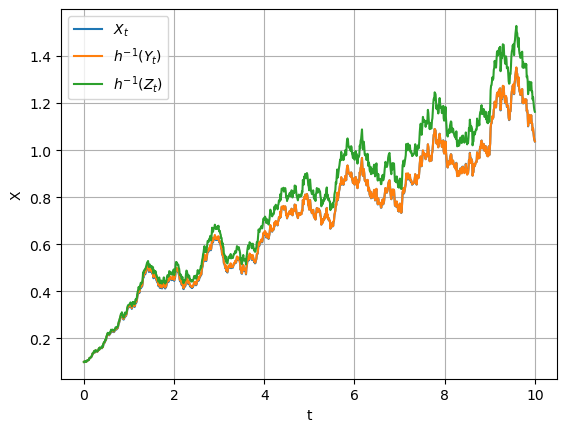

In [244]:
plt.plot(t, XL, label=r"$X_t$")
plt.plot(t, np.exp(sigma*YL), label=r"$h^{-1}(Y_t)$")
plt.plot(t, np.exp(sigma*ZL), label=r"$h^{-1}(Z_t)$")

plt.xlabel("t")
plt.ylabel("X")
plt.legend()
plt.grid()
plt.show()

### Exercise 5

sigma = 0.5
Mean = 0.7477727925454868
Variance = 0.07422071978232139

sigma = 1
Mean = 0.13972534718206184
Variance = 0.0029654026649213205

sigma = 2
Mean = 7.225104048162183e-06
Variance = 1.154655076901773e-10



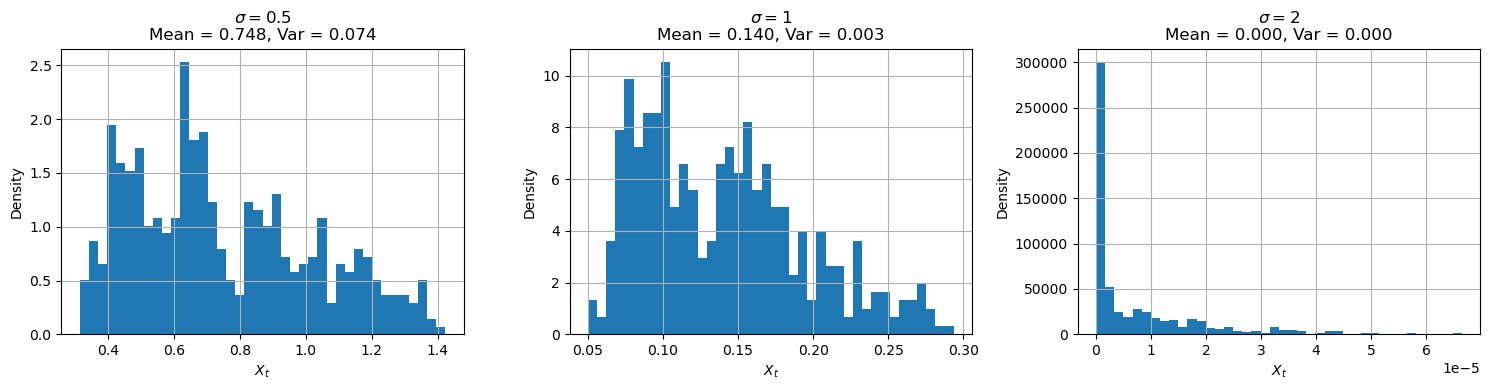

In [245]:
lmda = 1/2
chsi = 2

T = 10
dt = 0.01
x = 0.1

partition = np.linspace(0, T, int(T/dt))

sigmas = [0.5, 1, 2]


def eulersumL(f, g, T, dt, x):

    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    X[0] = x

    Bt = Brownian(partition)

    for i in range(1, N):

        X[i] = X[i-1] + f(X[i-1]) * dt + g(X[i-1]) * (Bt[i] - Bt[i-1])

    return t, X


fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for i, sigma in enumerate(sigmas):

    f = lambda x: x * (1 - x)
    g = lambda x: sigma * x

    t, XL = eulersumL(f, g, T, dt, x)

    XL_stationary = XL[len(XL)//2:]

    mean = np.mean(XL_stationary)
    variance = np.var(XL_stationary)

    axs[i].hist(XL_stationary, bins=40, density=True)

    axs[i].set_title(
        rf"$\sigma={sigma}$" + "\n" +
        rf"Mean = {mean:.3f}, Var = {variance:.3f}"
    )

    axs[i].set_xlabel(r"$X_t$")
    axs[i].set_ylabel("Density")
    axs[i].grid()

    print("sigma =", sigma)
    print("Mean =", mean)
    print("Variance =", variance)
    print()

plt.tight_layout()
plt.show()

Mean and variance in a the noisy harmonic oscillato

### Exercise 6

We have

$$
dX_t
=
AX_t\,dt
+
\sigma I\,dB_t,
$$

where

$$
A=
\begin{pmatrix}
0 & 1\\
-1 & 0
\end{pmatrix}.
$$

Taking expectation gives

$$
\frac{d}{dt}E[X_t]
=
AE[X_t],
$$

since

$$
E[dB_t]=0.
$$

We want to verify that

$$
E[X_t]
=
\begin{pmatrix}
\cos t & \sin t\\
-\sin t & \cos t
\end{pmatrix}x.
$$

Differentiating,

$$
\frac{d}{dt}E[X_t]
=
\begin{pmatrix}
-\sin t & \cos t\\
-\cos t & -\sin t
\end{pmatrix}x.
$$

On the other hand,

$$
AE[X_t]
=
\begin{pmatrix}
0 & 1\\
-1 & 0
\end{pmatrix}
\begin{pmatrix}
\cos t & \sin t\\
-\sin t & \cos t
\end{pmatrix}x
$$

which gives

$$
AE[X_t]
=
\begin{pmatrix}
-\sin t & \cos t\\
-\cos t & -\sin t
\end{pmatrix}x.
$$

Therefore,

$$
\frac{d}{dt}E[X_t]
=
AE[X_t],
$$

so the given expression for $E[X_t]$ is verified.

### Exercise 7

We define

$$
S_t=\|X_t\|^2=X_t^T X_t.
$$

Using Itô's lemma,

$$
dS_t
=
2X_t^T dX_t
+
dX_t^T dX_t.
$$

Since

$$
dX_t=AX_t\,dt+\sigma I\,dB_t,
$$

we get

$$
dS_t
=
2X_t^TAX_t\,dt
+
2\sigma X_t^T dB_t
+
2\sigma^2\,dt.
$$

Since

$$
X_t^TAX_t=0,
$$

due to antisymetri of the Matrix $A$.

we obtain

$$
dS_t
=
2\sigma^2\,dt
+
2\sigma X_t^T dB_t.
$$

Taking expectation and using

$$
E[dB_t]=0,
$$

gives

$$
\frac{d}{dt}E[S_t]=2\sigma^2.
$$

Therefore,

$$
E[S_t]
=
\|x\|^2+2\sigma^2 t.
$$

### Exercise 8

For the linear SDE

$$
dX_t=AX_t\,dt+G\,dB_t,
$$

the variance-covariance matrix $\Sigma_t$ satisfies the differential Lyapunov equation

$$
\dot{\Sigma}_t
=
A\Sigma_t+\Sigma_t A^T+GG^T.
$$

Here,

$$
A=
\begin{pmatrix}
0 & 1\\
-1 & 0
\end{pmatrix},
\qquad
G=\sigma I.
$$

We use the hint and assume

$$
\Sigma_t=
\begin{pmatrix}
\Sigma_t^{11} & 0\\
0 & \Sigma_t^{22}
\end{pmatrix}.
$$

Then

$$
A\Sigma_t+\Sigma_t A^T
=
\begin{pmatrix}
0 & \Sigma_t^{22}-\Sigma_t^{11}\\
\Sigma_t^{22}-\Sigma_t^{11} & 0
\end{pmatrix},
$$

and

$$
GG^T
=
\sigma^2 I.
$$

For $\Sigma_t$ to remain diagonal, we must have

$$
\Sigma_t^{11}=\Sigma_t^{22}.
$$

Therefore,

$$
\dot{\Sigma}_t^{11}=\sigma^2,
\qquad
\dot{\Sigma}_t^{22}=\sigma^2.
$$

Since $X_0=x$ is deterministic,

$$
\Sigma_0=0.
$$

Hence,

$$
\Sigma_t^{11}=\sigma^2 t,
\qquad
\Sigma_t^{22}=\sigma^2 t.
$$

Thus,

$$
\Sigma_t
=
\sigma^2 t
\begin{pmatrix}
1 & 0\\
0 & 1
\end{pmatrix}.
$$